In [4]:
# Correct Ofsted ANN architecture — matches the trained ofsted_ann.pt
class OfstedANN(nn.Module):
    def __init__(self, n_features=16, n_classes=4, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 32), nn.ReLU(), nn.Dropout(dropout),  # 16 → 32
            nn.Linear(32, 16),         nn.ReLU(), nn.Dropout(dropout),  # 32 → 16
            nn.Linear(16, n_classes),                                   # 16 → 4
        )
    def forward(self, x): return self.net(x)

model = OfstedANN()
model.load_state_dict(torch.load("../models/ofsted_ann.pt"))
model.eval()
print(f"Model loaded. Test set shape: {X_test.shape}")

Model loaded. Test set shape: (273, 16)


In [5]:
# For classification, SHAP needs predicted PROBABILITIES, not just class labels
def predict_proba_fn(X_numpy):
    with torch.no_grad():
        X_t = torch.FloatTensor(X_numpy)
        logits = model(X_t).numpy()
        # Convert logits to probabilities via softmax
        exp_logits = np.exp(logits - logits.max(axis=1, keepdims=True))
        probs = exp_logits / exp_logits.sum(axis=1, keepdims=True)
    return probs

# Background sample from training data (SHAP's reference distribution)
background = shap.sample(X_train, 100, random_state=SEED)

explainer = shap.KernelExplainer(predict_proba_fn, background)
print("SHAP explainer created.")
print(f"Baseline (expected class probabilities): {explainer.expected_value}")

SHAP explainer created.
Baseline (expected class probabilities): [0.14286987 0.23188439 0.3592405  0.26600524]


In [6]:
# Compute SHAP on a sample of test schools (full set is slow — 100 is plenty)
n_explain = 100
X_explain = X_test[:n_explain]
shap_values = explainer.shap_values(X_explain, nsamples=100)

# shap_values is a list of 4 arrays (one per class)
# OR a single 3D array (n_schools, n_features, n_classes) in newer SHAP versions
print(f"SHAP values type: {type(shap_values)}")
if isinstance(shap_values, list):
    print(f"List of {len(shap_values)} arrays, each shape: {shap_values[0].shape}")
else:
    print(f"Array shape: {shap_values.shape}")

  0%|          | 0/100 [00:00<?, ?it/s]

SHAP values type: <class 'numpy.ndarray'>
Array shape: (100, 16, 4)


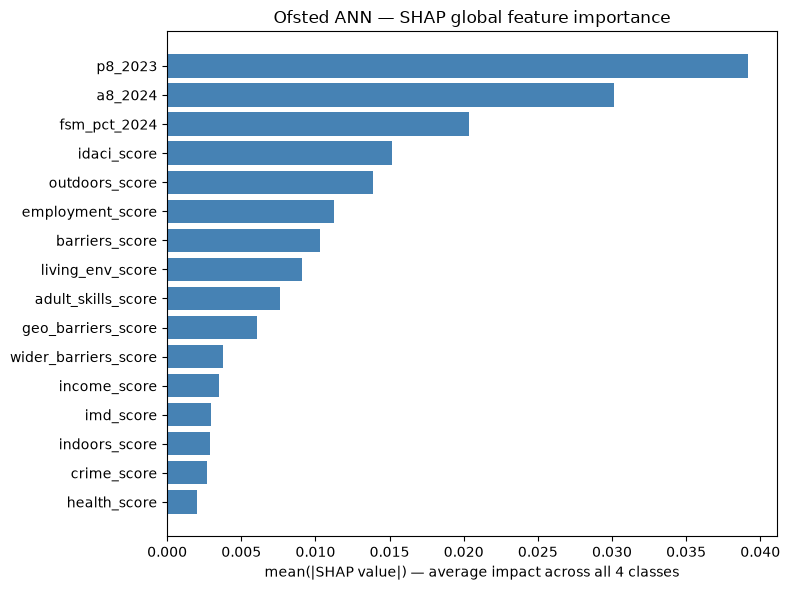


Top 5 features by SHAP importance:
       feature  mean_abs_shap
       p8_2023       0.039141
       a8_2024       0.030144
  fsm_pct_2024       0.020326
   idaci_score       0.015186
outdoors_score       0.013888


In [ ]:
# Convert to 3D array if needed for consistent handling
if isinstance(shap_values, list):
    shap_array = np.stack(shap_values, axis=-1)  # (n_schools, n_features, n_classes)
else:
    shap_array = shap_values

# Mean absolute SHAP per feature across all classes
mean_abs_shap = np.abs(shap_array).mean(axis=(0, 2))
importance_df = pd.DataFrame({
    "feature": numeric_features,
    "mean_abs_shap": mean_abs_shap,
}).sort_values("mean_abs_shap", ascending=True)  # ascending for horizontal bar plot

plt.figure(figsize=(8, 6))
plt.barh(importance_df["feature"], importance_df["mean_abs_shap"], color="steelblue")
plt.xlabel("mean(|SHAP value|) — average impact across all 4 classes")
plt.title("Ofsted ANN — SHAP global feature importance")
plt.tight_layout()
plt.savefig("../SRC/EDA/fig_ofsted_shap_importance.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nTop 5 features by SHAP importance:")
print(importance_df.sort_values("mean_abs_shap", ascending=False).head().to_string(index=False))

C:\Users\modne\AppData\Local\Temp\ipykernel_28624\865586936.py:9: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


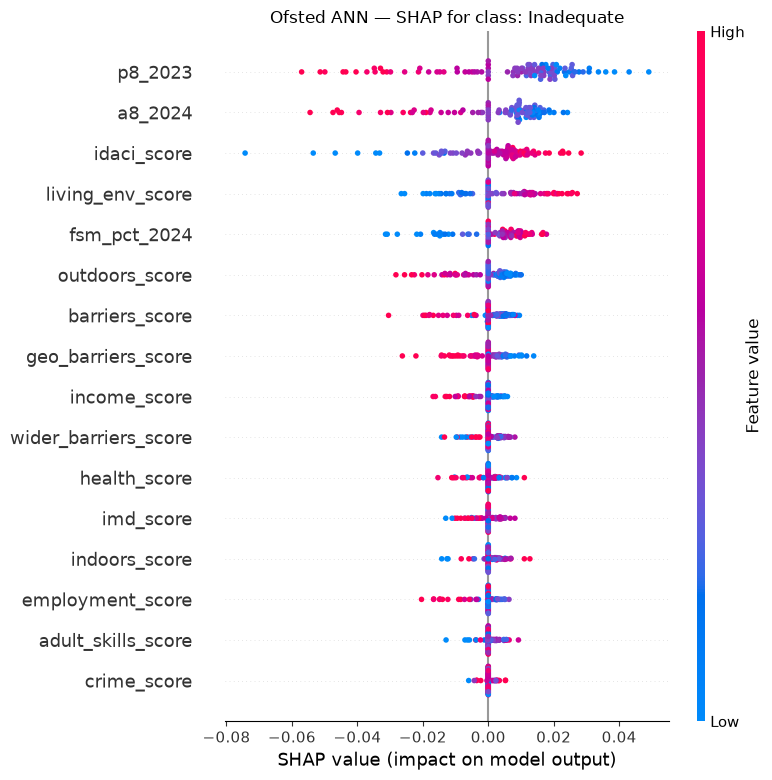

C:\Users\modne\AppData\Local\Temp\ipykernel_28624\865586936.py:9: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


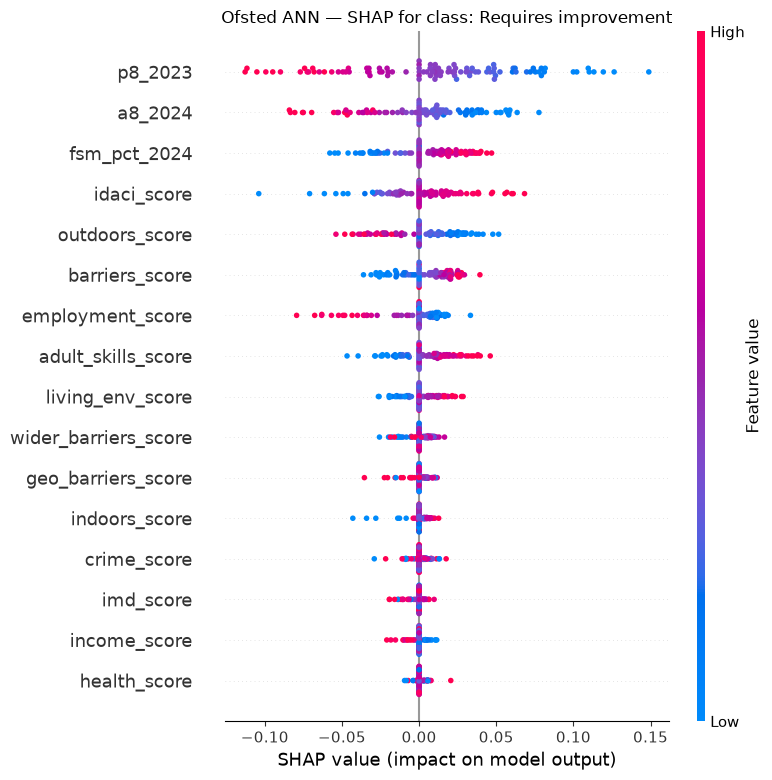

C:\Users\modne\AppData\Local\Temp\ipykernel_28624\865586936.py:9: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


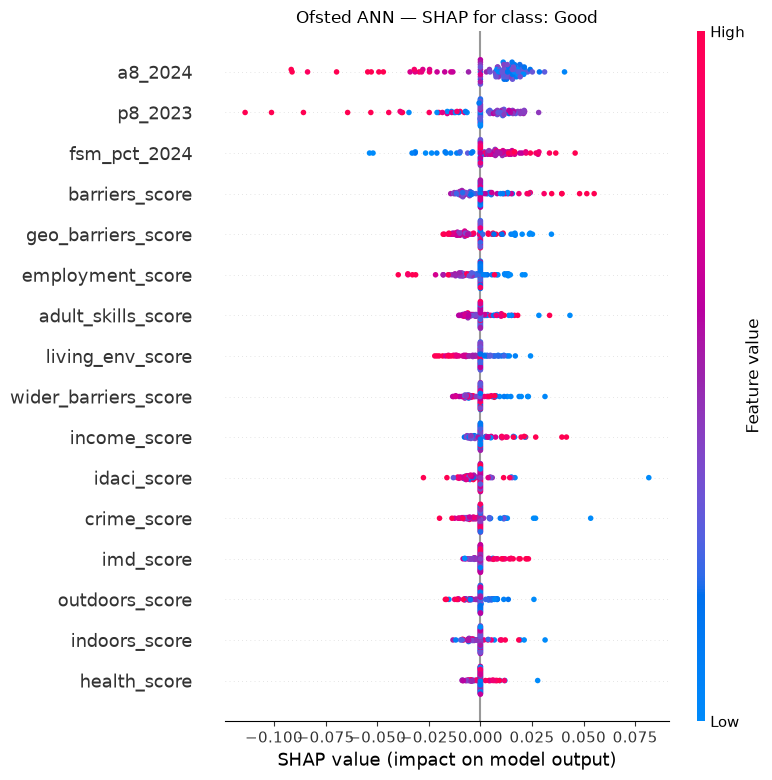

C:\Users\modne\AppData\Local\Temp\ipykernel_28624\865586936.py:9: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


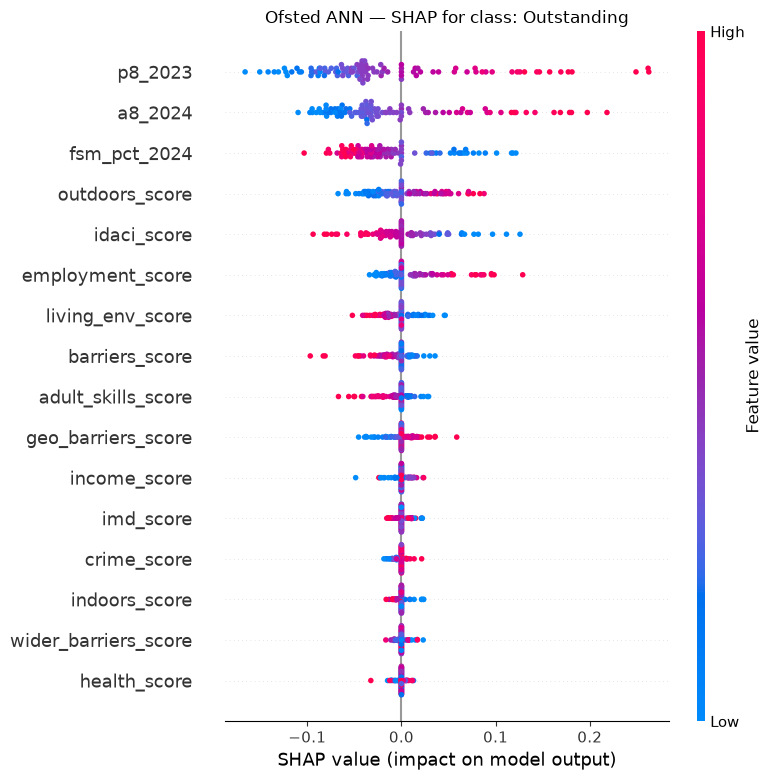

In [8]:
# Show SHAP contribution to each class separately
for class_idx, class_name in enumerate(grade_labels):
    # Get SHAP values for this specific class
    if isinstance(shap_values, list):
        class_shap = shap_values[class_idx]
    else:
        class_shap = shap_values[:, :, class_idx]

    shap.summary_plot(
        class_shap, X_explain,
        feature_names=numeric_features,
        show=False,
        max_display=16,
    )
    plt.title(f"Ofsted ANN — SHAP for class: {class_name}")
    plt.tight_layout()
    safe_name = class_name.lower().replace(" ", "_")
    plt.savefig(f"../SRC/EDA/fig_ofsted_shap_beeswarm_{safe_name}.png",
                dpi=150, bbox_inches="tight")
    plt.show()

School #0:
  Actual class:    Good (2)
  Predicted class: Requires improvement (1)


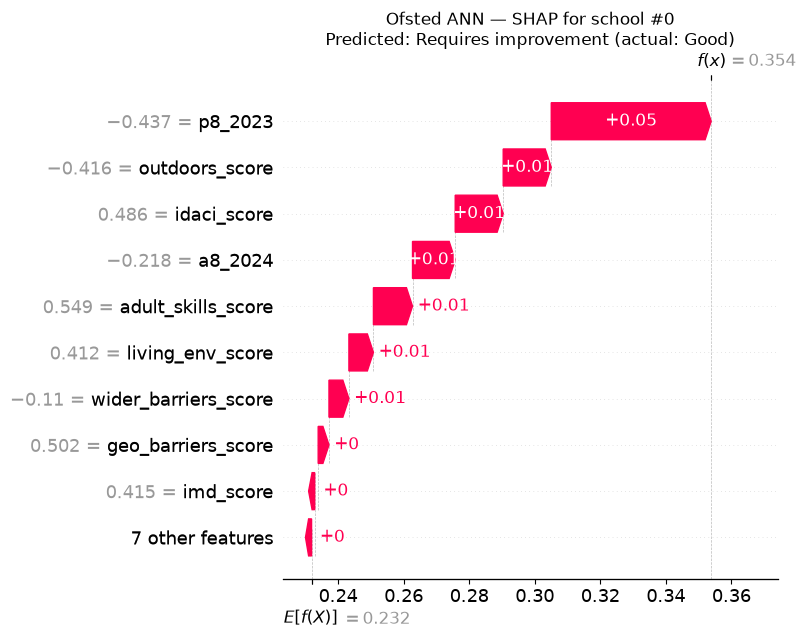

In [9]:
# Pick a specific school to explain — e.g. first school in explained set
school_idx = 0

# Get the predicted class for this school
with torch.no_grad():
    school_input = torch.FloatTensor(X_explain[school_idx:school_idx+1])
    predicted_class = model(school_input).argmax(dim=1).item()

actual_class = y_test[school_idx]

print(f"School #{school_idx}:")
print(f"  Actual class:    {grade_labels[actual_class]} ({actual_class})")
print(f"  Predicted class: {grade_labels[predicted_class]} ({predicted_class})")

# Waterfall plot for the PREDICTED class
if isinstance(shap_values, list):
    shap_for_class = shap_values[predicted_class][school_idx]
    base_for_class = explainer.expected_value[predicted_class]
else:
    shap_for_class = shap_values[school_idx, :, predicted_class]
    base_for_class = explainer.expected_value[predicted_class]

explanation = shap.Explanation(
    values=shap_for_class,
    base_values=base_for_class,
    data=X_explain[school_idx],
    feature_names=numeric_features,
)

shap.waterfall_plot(explanation, show=False)
plt.title(f"Ofsted ANN — SHAP for school #{school_idx}\n"
          f"Predicted: {grade_labels[predicted_class]} (actual: {grade_labels[actual_class]})")
plt.tight_layout()
plt.savefig(f"../SRC/EDA/fig_ofsted_shap_waterfall_school{school_idx}.png",
            dpi=150, bbox_inches="tight")
plt.show()